# Mall Customer Segmentation 
#### KMeans, Hierarchical and DBSCAN
**Subject:** Unsupervised Learning

**Dataset:** Mall Customers (Kaggle) - https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

In this notebook I group the 200 mall customers into segments using three unsupervised algorithms and compare them.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

## Task 1: Data Loading & Exploratory Data Analysis (EDA)

In [3]:
df = pd.read_csv("../Dataset/Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
print('Shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0


**1.2 Rename and drop columns** - **CustomerID** is only an ID so it is dropped, and the long column names are shortened.

In [7]:
df = df.rename(columns={'Annual Income (k$)': 'Annual_Income', 'Spending Score (1-100)': 'Spending_Score'})
df = df.drop(columns='CustomerID')
df.head()

,Gender,Age,Annual_Income,Spending_Score
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


**1.3 Encode Gender** - **LabelEncoder** gives Female = 0 and Male = 1 (alphabetical order), which is what we want.

In [8]:
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])
print(dict(zip(le.classes_, le.transform(le.classes_))))
df.head()

{'Female': np.int64(0), 'Male': np.int64(1)}


,Gender,Age,Annual_Income,Spending_Score
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


**1.4 Univariate distributions** - histograms with a KDE curve for each numeric feature.

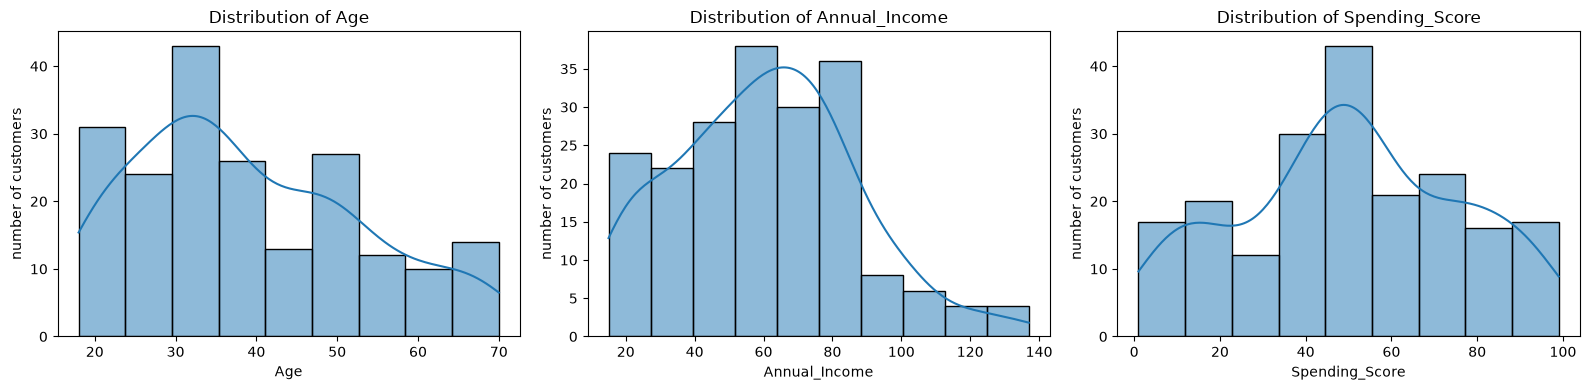

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Age', 'Annual_Income', 'Spending_Score']):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('number of customers')

plt.tight_layout()
plt.savefig("../Images/01_histograms.png")
plt.show()

**1.5 Pairplot and correlation heatmap**

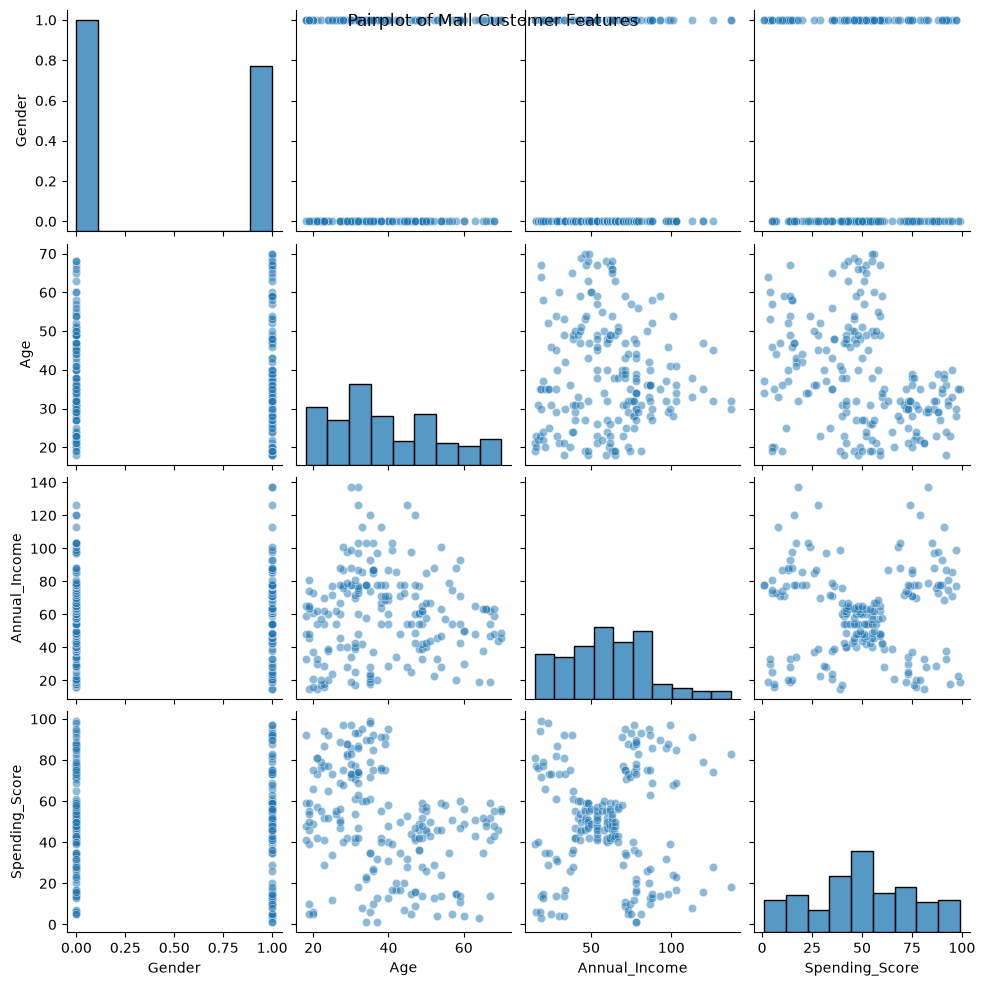

In [10]:
g = sns.pairplot(df, plot_kws={'alpha': 0.5})
g.figure.suptitle('Pairplot of Mall Customer Features')
g.savefig('../Images/02_pairplot.png', dpi=120, bbox_inches='tight')
plt.show()

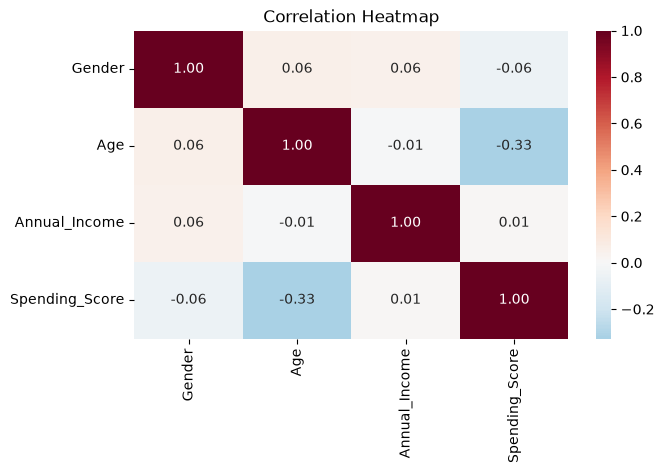

In [11]:
plt.figure(figsize=(7, 4))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation Heatmap')
plt.savefig('../Images/03_correlation_heatmap.png')
plt.show()

**1.6 EDA Summary**

- The dataset is clean: 200 rows, 4 columns after cleaning, no missing values and no duplicates.
- Age is mostly between 20 and 50, Annual_Income is a bit right-skewed (a few customers earn more than 100k$), and Spending_Score is spread out across the full 1-100 range.
- All the correlations are weak. The only noticeable one is Age vs Spending_Score (about -0.33): younger customers tend to have a higher spending score. Income and Spending_Score are almost uncorrelated, which means a simple straight-line relation will not explain the data - clusters might.
- In the pairplot, the **Annual_Income vs Spending_Score** panel shows clear separate blobs (around five groups), while the panels with Age look like one big cloud.
- So I choose **Annual_Income vs Spending_Score** as the two features for clustering: it shows the most visible groups, and the groups also make business sense (how much a customer can spend vs how much the customer actually spends).

## Task 2: Feature Scaling & Feature Selection

In [12]:
features = ['Age', 'Annual_Income', 'Spending_Score']
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[features]), columns=features)
df_scaled.describe()

,Age,Annual_Income,Spending_Score
count,2.000000e+02,2.000000e+02,2.000000e+02
mean,-1.021405e-16,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00,1.002509e+00
min,-1.496335e+00,-1.738999e+00,-1.910021e+00
25%,-7.248436e-01,-7.275093e-01,-5.997931e-01
50%,-2.045351e-01,3.587926e-02,-7.764312e-03
75%,7.284319e-01,6.656748e-01,8.851316e-01
max,2.235532e+00,2.917671e+00,1.894492e+00


In [13]:
df_2f = df_scaled[['Annual_Income', 'Spending_Score']]
df_2f.head()

,Annual_Income,Spending_Score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


**2.2 Why 2 features?** The main tasks use **Annual_Income and Spending_Score** because the clusters are clearly visible in 2D and we can plot them directly without PCA. Using all 4 features is also valid, so I test it as an extension in Task 6.

**2.3 Why do we scale?** K-Means, Hierarchical (Ward) and DBSCAN are all *distance-based*: they decide cluster membership by measuring the distance between points. If features are on different scales, the feature with the bigger numbers dominates the distance. Annual_Income ranges from about 15 to 137 while Spending_Score ranges from 1 to 100, so income would count more than spending score just because of its larger range. **StandardScaler** converts every feature to mean 0 and standard deviation 1, so each feature gets a fair say. Gender is already 0/1, so it is not scaled.

## Task 3: K-Means Clustering

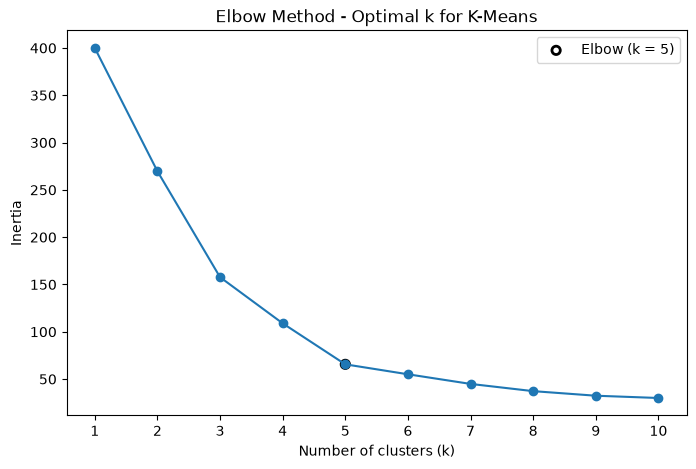

In [14]:
inertias = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(df_2f)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))    
plt.plot(list(k_range), inertias, marker='o')
plt.scatter(5, inertias[4], facecolor='none', edgecolors='black', linewidths=2, label='Elbow (k = 5)')
plt.title('Elbow Method - Optimal k for K-Means')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_range))
plt.legend()
plt.savefig('../Images/04_elbow_method.png')
plt.show()

**3.1 What is inertia?** Inertia is the sum of squared distances between every point and the centre of its own cluster. A smaller inertia means the points are packed tightly around their centroids. Inertia always goes down when k increases (at k = 200 it would be 0), so we cannot just pick the smallest value. We look for the *elbow*: the point after which adding more clusters gives only a small improvement. In the plot the curve drops steeply until k = 5 and then flattens, so **k = 5** is the elbow.

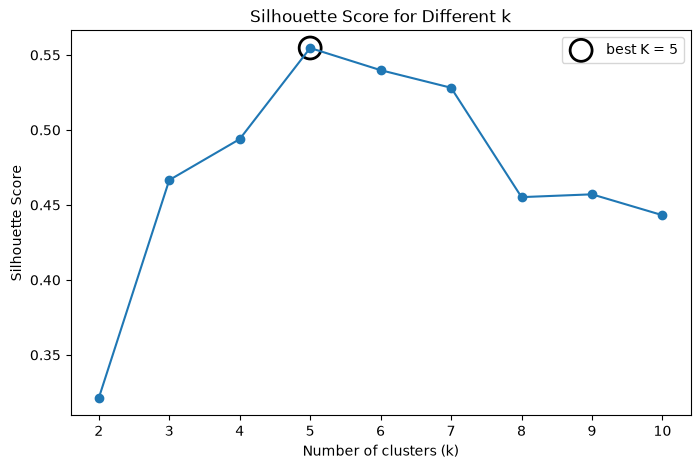

Best k by silhouette: 5 | score = 0.5547


In [15]:
sil_score = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(df_2f)
    sil_score.append(silhouette_score(df_2f, labels))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), sil_score, marker='o')
best_k = range(2, 11)[int(np.argmax(sil_score))]
plt.scatter(best_k, max(sil_score), s=250, facecolor='none', edgecolors='black', linewidths=2, label=f'best K = {best_k}')
plt.title('Silhouette Score for Different k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.savefig('../Images/05_silhouette_scores.png')
plt.show()
print('Best k by silhouette:', best_k, '| score =', round(max(sil_score), 4))

**3.2 Elbow vs Silhouette:** The silhouette score tells how well each point fits in its own cluster compared with the nearest other cluster (closer to 1 is better). It is highest at **k = 5** (about 0.55), which is the same as the elbow, so both methods agree. The elbow is judged by eye and can be a little subjective, while the silhouette gives one number. Since they agree, I use **k = 5**.

In [16]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10).fit(df_2f)
df['KMeans_Cluster'] = kmeans.labels_
df['KMeans_Cluster'].value_counts().sort_index()

KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

**3.4 Visualise K-Means clusters** - the centroids are calculated on scaled data, so I convert them back to the original units (k$ and score) before plotting them on the original axes.

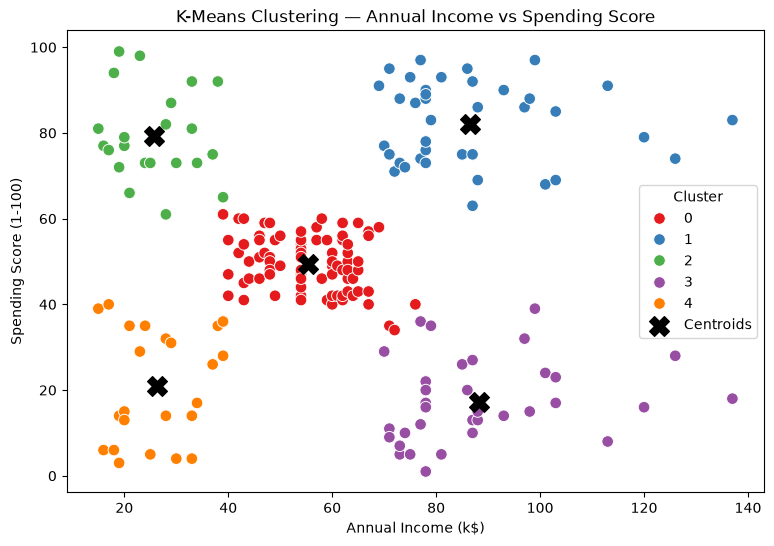

In [17]:
centers = kmeans.cluster_centers_ * scaler.scale_[1:] + scaler.mean_[1:]

plt.figure(figsize=(9, 6))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Cluster', data=df, palette='Set1', s=70)
plt.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=200, label='Centroids')
plt.title('K-Means Clustering — Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.savefig('../Images/06_kmeans_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
kmeans_profile = df.groupby('KMeans_Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean().round(1)
kmeans_profile['Customers'] = df['KMeans_Cluster'].value_counts().sort_index()
kmeans_profile

,Age,Annual_Income,Spending_Score,Customers
KMeans_Cluster,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


**3.5 Segment names and business meaning (K-Means)**

| Cluster | Segment name | What they look like | Business implication |
|---|---|---|---|
| 0 | Average Customers | middle income (~55k$), middle spending (~50), age ~43 | Largest group; steady customers who can be nudged to spend more with offers |
| 1 | High Income, High Spenders | income ~87k$, score ~82, age ~33 | Best customers; keep them happy with premium treatment |
| 2 | Low Income, High Spenders | income ~26k$, score ~79, age ~25 | Young and enthusiastic; they respond to trends and discounts |
| 3 | High Income, Low Spenders | income ~88k$, score ~17, age ~41 | Have money but do not spend in this mall; big opportunity if we find what they want |
| 4 | Low Income, Low Spenders | income ~26k$, score ~21, age ~45 | Careful with money; low priority for expensive campaigns |

## Task 4: Agglomerative Hierarchical Clustering

In [19]:
Z = linkage(df_2f, method='ward')

heights = Z[:, 2]
gaps = np.diff(heights)
biggest = np.argmax(gaps)
cut_height = (heights[biggest] + heights[biggest + 1]) / 2
n_clusters_cut = len(heights) - biggest

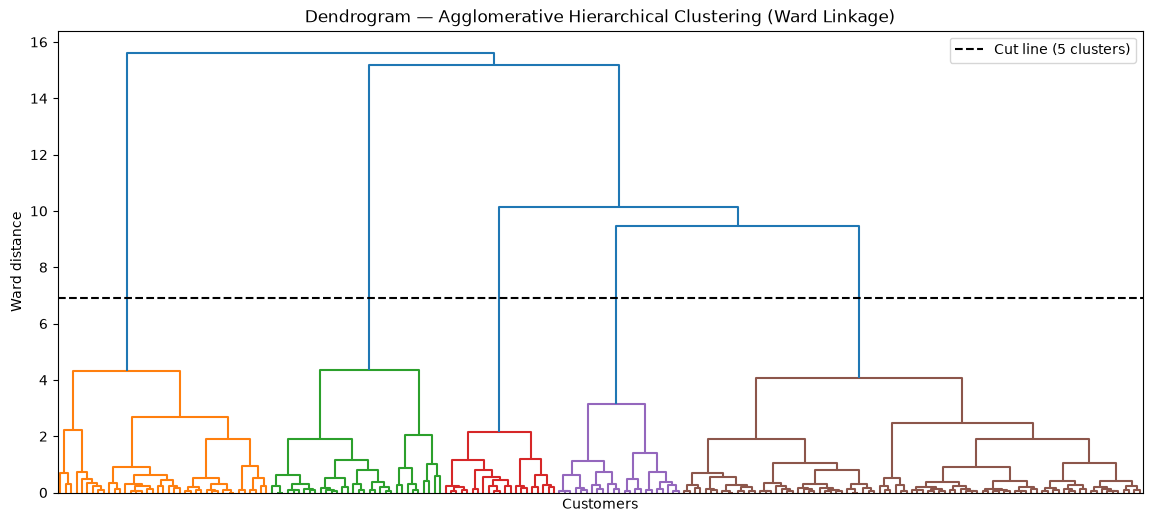

Clusters at that cut: 5


In [20]:
plt.figure(figsize=(14, 6))
dendrogram(Z, no_labels=True, color_threshold=cut_height)
plt.axhline(y=cut_height, color='black', linestyle='--', label=f'Cut line ({n_clusters_cut} clusters)')
plt.title('Dendrogram — Agglomerative Hierarchical Clustering (Ward Linkage)')
plt.xlabel('Customers')
plt.ylabel('Ward distance')
plt.legend()
plt.savefig('../Images/07_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

print('Clusters at that cut:', n_clusters_cut)

**4.1 Ward linkage and reading the dendrogram:** Hierarchical clustering starts with every customer as its own cluster and keeps merging the two closest clusters until only one is left. *Ward linkage* chooses the merge that increases the total within-cluster variance (sum of squared distances to the cluster centre) the least, so it makes compact, similar-sized clusters - similar in spirit to K-Means.

In the dendrogram the height of a vertical line is the distance at which two clusters were merged. Long vertical lines mean we are forcing very different groups together. To choose the number of clusters, we draw a horizontal line through the **longest vertical distance that no horizontal branch crosses**; the number of vertical lines it cuts is the number of clusters. The dashed line cuts through 5 branches, so we use **5 clusters**, which agrees with K-Means.

In [21]:
hier = AgglomerativeClustering(n_clusters=5, linkage='ward')
df['Hier_Cluster'] = hier.fit_predict(df_2f)
df['Hier_Cluster'].value_counts().sort_index()

Hier_Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

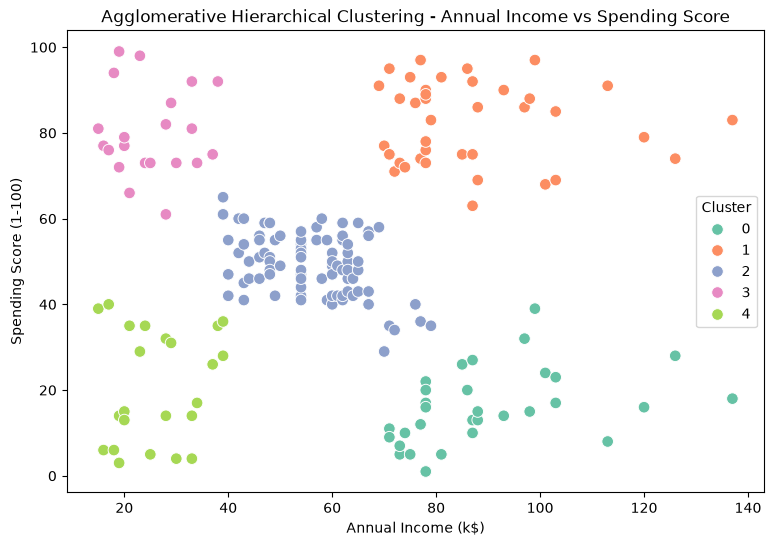

In [22]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hier_Cluster', data=df, palette='Set2', s=70)
plt.title('Agglomerative Hierarchical Clustering - Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.savefig('../Images/08_hierarchical_clusters.png')
plt.show()

**4.4 Compare with K-Means.** Cluster numbers are just names and are given randomly, so first I match each hierarchical cluster to the K-Means cluster it overlaps the most. That way the same segment has the same colour in both plots.

In [23]:
overlap = pd.crosstab(df['Hier_Cluster'], df['KMeans_Cluster'])
display(overlap)
match = overlap.idxmax(axis=1)
df['Hier_Matched'] = df['Hier_Cluster'].map(match)
disagree = df[df['Hier_Matched'] != df['KMeans_Cluster']]
print('Customers placed in a different segment by the two methods:', len(disagree))

KMeans_Cluster,0,1,2,3,4
Hier_Cluster,,,,,
0,0,0,0,32,0
1,0,39,0,0,0
2,81,0,1,3,0
3,0,0,21,0,0
4,0,0,0,0,23


Customers placed in a different segment by the two methods: 4


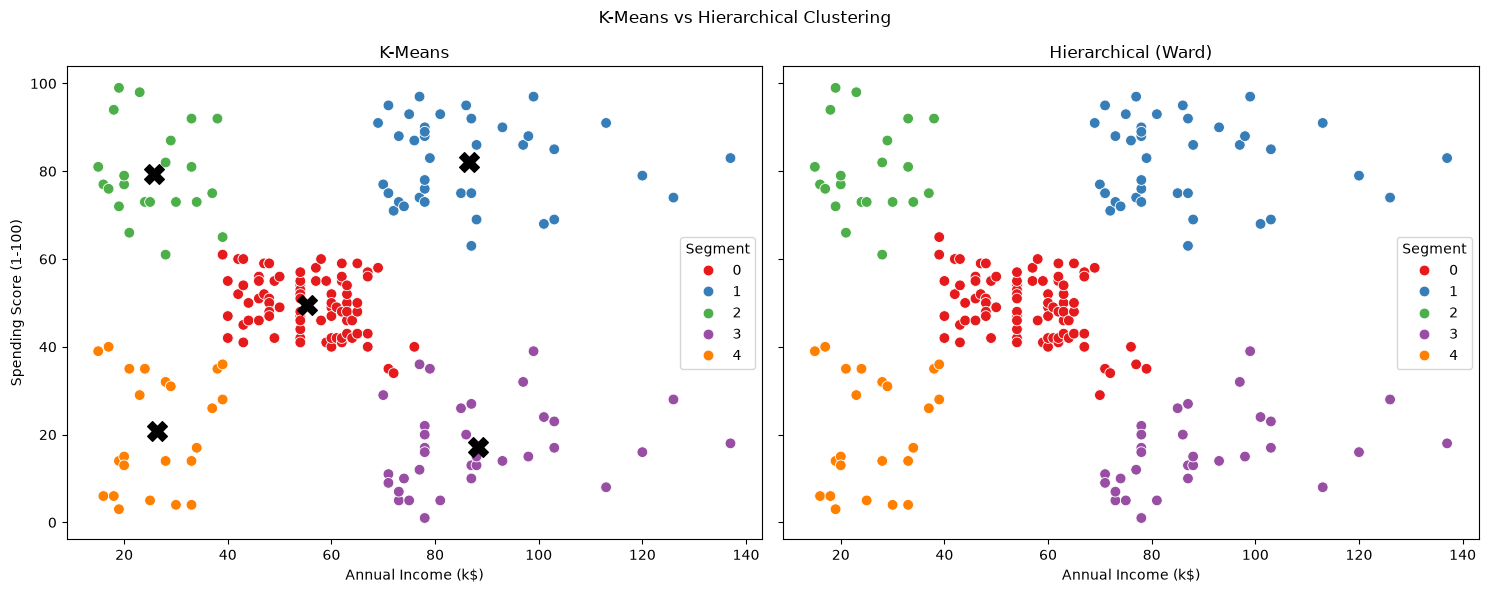

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans_Cluster', data=df, palette='Set1', s=60, ax=axes[0])
axes[0].scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=200)
axes[0].set_title('K-Means')
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hier_Matched', data=df, palette='Set1', s=60, ax=axes[1])
axes[1].set_title('Hierarchical (Ward)')

for ax in axes:
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')
    ax.legend(title='Segment')

fig.suptitle('K-Means vs Hierarchical Clustering')
plt.tight_layout()
plt.savefig('../Images/09_kmeans_vs_hierarchical.png')
plt.show()

**Do the two methods agree?** Yes, almost completely: only a few customers (listed above) get a different label, and all of them lie on the **borders between neighbouring segments**: 3 are on the edge between the average group and the high-income / low-spending group, and 1 is on the edge between the average group and the low-income / high-spending group. The reason is how the two methods work:

- **K-Means (centroid based)** assigns each point to the nearest centroid, so the border is a straight line exactly halfway between two centres.
- **Hierarchical (connectivity based)** builds clusters by merging step by step using the Ward criterion, so a border point is placed where it increases the variance the least at the time of merging. This can differ a little from the nearest-centroid rule.

When the groups are well separated, as here, both give nearly the same answer.

In [25]:
hier_profile = df.groupby('Hier_Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean().round(1)
hier_profile['Customers'] = df['Hier_Cluster'].value_counts().sort_index()
hier_profile

,Age,Annual_Income,Spending_Score,Customers
Hier_Cluster,,,,
0,41.0,89.4,15.6,32
1,32.7,86.5,82.1,39
2,42.5,55.8,49.1,85
3,25.3,25.1,80.0,21
4,45.2,26.3,20.9,23


**4.5 Profile comparison:** The hierarchical profiles are very close to the K-Means profiles (the cluster numbers are different, but the segments are the same):

- Hier 1 ≈ K-Means 1 → High Income, High Spenders (both 39 customers)
- Hier 3 ≈ K-Means 2 → Low Income, High Spenders
- Hier 4 ≈ K-Means 4 → Low Income, Low Spenders (identical average values)
- Hier 0 ≈ K-Means 3 → High Income, Low Spenders
- Hier 2 ≈ K-Means 0 → Average Customers

So the segment definitions are consistent between the two methods.

## Task 5: DBSCAN Clustering

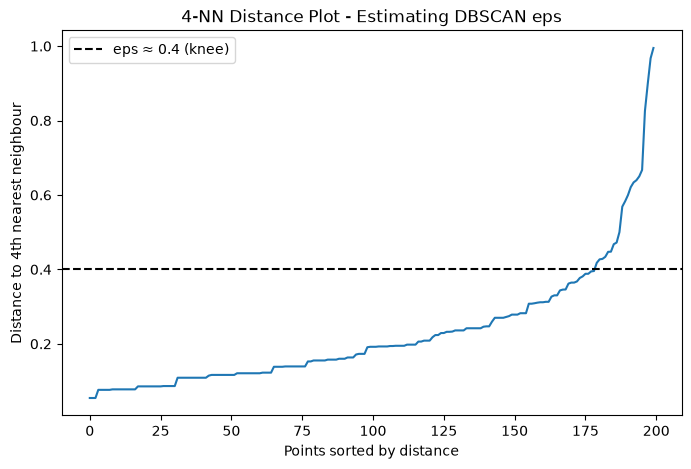

In [26]:
nn = NearestNeighbors(n_neighbors=4).fit(df_2f)
distances, _ = nn.kneighbors(df_2f)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_dist)
plt.axhline(0.4, color='black', linestyle='--', label='eps ≈ 0.4 (knee)')
plt.title('4-NN Distance Plot - Estimating DBSCAN eps')
plt.xlabel('Points sorted by distance')
plt.ylabel('Distance to 4th nearest neighbour')
plt.legend()
plt.savefig('../Images/10_k_distance_plot.png')
plt.show()

**5.1 Reading the plot:** Most points have a 4th-neighbour distance below about 0.4; after that the curve bends sharply upward - these are the lonely points far from everyone else. The knee is around **eps ≈ 0.4**, so I use that as the starting point for the grid search.

In [27]:
rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 4, 5, 6]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(df_2f)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        sil = silhouette_score(df_2f[mask], labels[mask]) if n_clusters > 1 else np.nan
        rows.append({'eps': eps, 'min_samples': ms, 'n_clusters': n_clusters,
                     'n_noise': int((~mask).sum()), 'silhouette': round(sil, 3)})

grid = pd.DataFrame(rows)
grid.head()

,eps,min_samples,n_clusters,n_noise,silhouette
0,0.2,3,13,44,0.470
1,0.2,4,5,73,0.617
2,0.2,5,7,77,0.586
3,0.2,6,4,95,0.614
4,0.3,3,9,14,0.472


**5.2 Choosing the parameters:**

- Very small **eps** (0.2) produces many noise points (44 to 95 customers), so most of the data is thrown away.
- Large **eps** (0.5 and above) joins everything into only 1 or 2 clusters.
- **eps = 0.4** is the best balance and matches the knee of the k-distance plot. With **min_samples = 5** it gives **4 clusters with 15 noise points** and a silhouette of about 0.48, so I choose **eps = 0.4, min_samples = 5**.

In [28]:
dbscan = DBSCAN(eps=0.4, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(df_2f)
df['DBSCAN_Cluster'].value_counts().sort_index()

DBSCAN_Cluster
-1     15
 0    115
 1     11
 2     32
 3     27
Name: count, dtype: int64

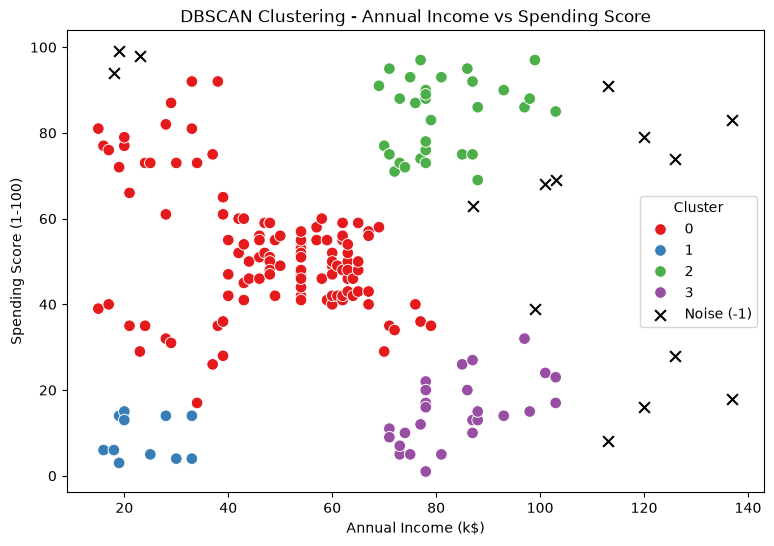

In [29]:
clustered = df[df['DBSCAN_Cluster'] != -1]
noise = df[df['DBSCAN_Cluster'] == -1]

plt.figure(figsize=(9, 6))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='DBSCAN_Cluster', data=clustered, palette='Set1', s=70)
plt.scatter(noise['Annual_Income'], noise['Spending_Score'], c='black', marker='x', s=60, label='Noise (-1)')
plt.title('DBSCAN Clustering - Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.savefig('../Images/11_dbscan_clusters.png')
plt.show()

**5.4 What do **eps** and **min_samples** control?**

- **eps** is the radius of the neighbourhood around a point. Bigger **eps** → clusters merge; smaller **eps** → clusters break up and more points become noise.
- **min_samples** is how many points must be inside that radius for a point to be a *core point*. Bigger value → stricter, so more noise.
- **Noise points** (label −1) are points that are not core points and are not close enough to any core point. In this data they are mostly high-income customers (average income about 96k$) sitting between the dense groups, so they are far from every dense region.

**5.5 DBSCAN vs K-Means**

1. DBSCAN does not need k in advance: it finds the number of clusters from the density of the data. K-Means needs k (we used Elbow and Silhouette).
2. DBSCAN can find clusters of any shape; K-Means assumes round (spherical) clusters of similar size.
3. DBSCAN marks low-density points as noise; K-Means forces every customer into some cluster.
4. DBSCAN is sensitive to **eps**, and works badly when clusters have different densities. Here it merged the low-income / high-spending group into the large middle group, because they touch each other.
5. **Do the three algorithms agree?** K-Means and Hierarchical both give **5 segments** and agree on almost every customer. DBSCAN gives **4 clusters + noise**. The most stable segments in all three methods are **High Income / High Spenders** and **High Income / Low Spenders**, because they are far away from other groups (Low Income / Low Spenders is found by all three too, but DBSCAN keeps only part of it as a separate cluster).  The least stable area is the middle of the plot, where the Average group touches its neighbours.

## Task 6: Algorithm Comparison & Business Insights

In [30]:
def get_metrics(name, labels):
    labels = np.asarray(labels)
    mask = labels != -1
    X = df_2f.values[mask]
    y = labels[mask]
    return {'Algorithm': name,
            'n_clusters': len(set(y)),
            'Noise points': int((~mask).sum()),
            'Silhouette Score': round(silhouette_score(X, y), 3),
            'Davies-Bouldin (lower is better)': round(davies_bouldin_score(X, y), 3),
            'Calinski-Harabasz (higher is better)': round(calinski_harabasz_score(X, y), 1)}

metrics = pd.DataFrame([
    get_metrics('K-Means', df['KMeans_Cluster']),
    get_metrics('Hierarchical (Ward)', df['Hier_Cluster']),
    get_metrics('DBSCAN', df['DBSCAN_Cluster']),
])
metrics

,Algorithm,n_clusters,Noise points,Silhouette Score,Davies-Bouldin (lower is better),Calinski-Harabasz (higher is better)
0,K-Means,5,0,0.555,0.572,248.6
1,Hierarchical (Ward),5,0,0.554,0.578,244.4
2,DBSCAN,4,15,0.478,0.591,146.9


**6.2 Which algorithm is best?** K-Means and Hierarchical have almost identical scores (silhouette ≈ 0.55, the best Davies-Bouldin and the highest Calinski-Harabasz), with K-Means slightly ahead on all three. DBSCAN has lower scores, and its numbers are calculated after removing the noise points, so it is not a fully fair comparison. Overall **K-Means performs best** on this dataset because the groups are compact and roughly round, which is exactly the shape K-Means expects.

**Extension - using all 4 features.** The task said that using all features is also valid, so here is a quick test of K-Means with Gender, Age, Income and Spending Score together (k = 5).

In [31]:
df_4f = pd.concat([df[['Gender']], df_scaled], axis=1)
labels_4f = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(df_4f)
print('Silhouette with 4 features:', round(silhouette_score(df_4f, labels_4f), 3))
print('Silhouette with 2 features:', round(silhouette_score(df_2f, df['KMeans_Cluster']), 3))

Silhouette with 4 features: 0.35
Silhouette with 2 features: 0.555


The silhouette score drops with 4 features, because Age and Gender add overlap between the groups. This confirms that Annual_Income and Spending_Score are the best pair for separating customers, and the 2D plots are also much easier to explain.

### 6.3 Business Insights for Mall Management

**(a) Customer segments (from K-Means) and (b) one marketing action each**

| Segment | Size | Description | Recommended marketing action |
|---|---|---|---|
| High Income, High Spenders (cluster 1) | 39 | Wealthy, spend a lot, average age ~33 | **Loyalty / VIP rewards** - early access to sales, premium membership and exclusive events |
| Low Income, High Spenders (cluster 2) | 22 | Young (~25), spend a lot on a small income | **Budget promotions** - student and festival discounts, buy-more-save-more and cashback deals |
| High Income, Low Spenders (cluster 3) | 35 | Can afford more but spend little (score ~17) | **Personalised offers** - luxury brand stores, personal shopping and targeted emails to find out what interests them |
| Low Income, Low Spenders (cluster 4) | 23 | Price-sensitive, older (~45), low spending | **Low-cost offers** - coupons and essential-item discounts; avoid expensive campaigns |
| Average Customers (cluster 0) | 81 | Middle income and spending, the largest group | **Upselling campaigns** - combo offers and points that grow with the amount spent |

**(c) Which algorithm to recommend?**

I recommend **K-Means** for deployment. It gave the best metric scores, has simple and easy-to-explain segments (each has a centroid we can describe), and can quickly assign a new customer to a segment. Hierarchical clustering gives almost the same result and is useful when management wants to see the dendrogram hierarchy in a presentation. DBSCAN is the best choice when the cluster shapes are unknown or when we want to detect unusual customers (noise), but it needs careful tuning of **eps** and does not give a clean segment for every customer.

**Conclusion:** Using Annual_Income and Spending_Score, the mall customers fall naturally into 5 segments. The three algorithms mostly agree, which gives confidence that the segments are real and not just a result of one algorithm.